# CS413 Robotics — Lab 6: Differential-drive odometry, model vs real robot

**Student:** _name_ — **ID:** _…30_ — **Trajectory:** `30` — **Date:** _date_

Both runs use the same block program (`trajectory_sim.qrs`, `trajectory_real.qrs`); only the wheel radius `r`, the track width `B` and the log file name differ. Each log line is `x,y,time` (m, m, ms), no header.

**How to run:** put `odometry_data_sim.txt` and `odometry_data_real.txt` next to this notebook (in Colab: run the upload cell and select both files), then *Runtime → Run all*.

## 1. Odometry model

Per sample (encoders in degrees → radians):

$$\theta_{L,R} = \text{enc}_{L,R}\cdot\frac{\pi}{180},\qquad s = \frac{r(\theta_L+\theta_R)}{2},\qquad \varphi = \frac{r(\theta_R-\theta_L)}{B}$$

$$x \leftarrow x + \Delta s\cos\varphi,\qquad y \leftarrow y + \Delta s\sin\varphi$$

Left wheel = `M4`/`E4`, right wheel = `M3`/`E3`. The robot starts at the top-left corner of the "3", facing $+x$.

**Motion:** a list of 20 segments, run one after another every 20 ms (block *Function* "step"):
* **straight** — drive a distance, hold the segment heading ($w = K_H e$), slow down near the end;
* **turn** — turn on the spot to an absolute heading (0°, −90°, −180°, …), done when $|e| < 0.02$ rad;
* **pause** — 1.5 s between the "3" and the "0".

A segment ends when its distance, heading or time is reached (or after 8 s). The robot steers only by its own odometry.

| Run | `r`, m | `B`, m |
|---|---|---|
| simulator (TRIK 2D model) | 0.028 | 0.154 |
| real robot | 0.042 | 0.194 |

> **TODO:** measure `r` and `B` on your robot. If they differ, change them in the first *Function* block of `trajectory_real.qrs` and in the table above.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

SIM_FILE = 'odometry_data_sim.txt'
REAL_FILE = 'odometry_data_real.txt'
DATA_DIR = os.environ.get('LAB6_DATA_DIR', '.')
# the robot writes odm_240030.txt; use it if it was not renamed
if not os.path.exists(os.path.join(DATA_DIR, REAL_FILE)) and os.path.exists(os.path.join(DATA_DIR, 'odm_240030.txt')):
    REAL_FILE = 'odm_240030.txt'

# corners of the planned "30" (segment ends in the init block of the .qrs)
WAYPOINTS = np.array([(0, 0), (0.3, 0), (0.3, -0.3), (0.05, -0.3), (0.3, -0.3), (0.3, -0.6),
                      (0, -0.6), (0.75, -0.6), (0.75, 0), (0.45, 0), (0.45, -0.6)])

# real end point in the same frame (m)
MEASURED_END = (0.46, -0.81)

plt.rcParams.update({'axes.grid': True})

In [2]:
# Colab: upload the two log files if they are not present
missing = [f for f in (SIM_FILE, REAL_FILE) if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    try:
        from google.colab import files
        print('Upload:', missing)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'not found: {missing}')

## 2. Data
`time` → s from the first sample. Samples with a repeated time stamp are dropped (interpolation needs increasing time).

In [3]:
def load_log(name):
    x, y, t = np.loadtxt(os.path.join(DATA_DIR, name), delimiter=',', unpack=True, ndmin=2)
    keep = np.r_[True, np.diff(t) > 0]
    return x[keep], y[keep], (t[keep] - t[0]) / 1000

x_s, y_s, t_s = load_log(SIM_FILE)
x_r, y_r, t_r = load_log(REAL_FILE)


def path_length(x, y):
    return np.hypot(np.diff(x), np.diff(y)).sum()


print(f'{"":10s}{"samples":>9s}{"dt, ms":>9s}{"duration, s":>13s}{"path, m":>9s}{"end x, m":>10s}{"end y, m":>10s}')
for name, x, y, t in (('simulator', x_s, y_s, t_s), ('real', x_r, y_r, t_r)):
    print(f'{name:10s}{len(t):9d}{1000 * np.median(np.diff(t)):9.1f}{t[-1]:13.2f}'
          f'{path_length(x, y):9.3f}{x[-1]:10.3f}{y[-1]:10.3f}')

            samples   dt, ms  duration, s  path, m  end x, m  end y, m
simulator      2756     20.0        55.10    4.040     0.446    -0.600
real            528     61.0        32.93    4.819     0.460    -0.762


## 3. Trajectories

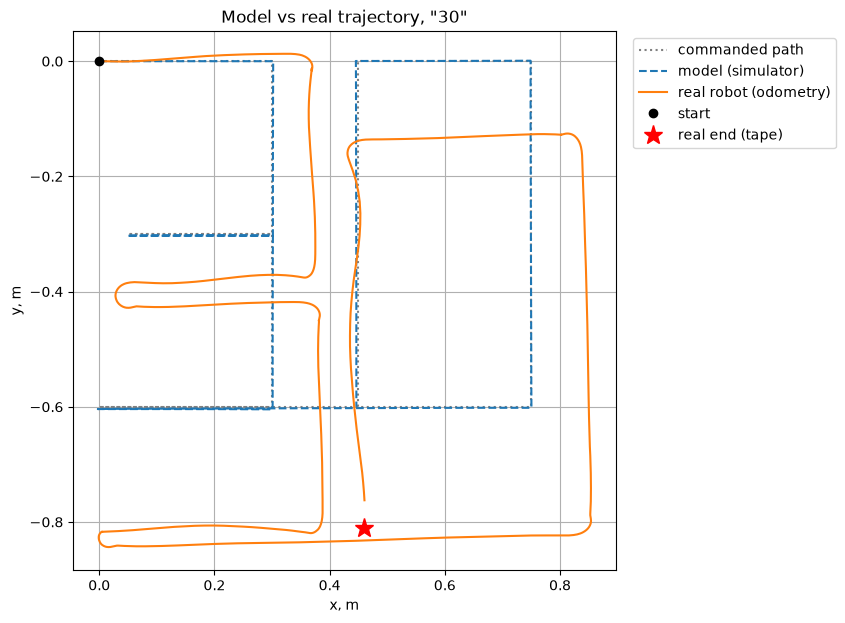

In [4]:
plt.figure(figsize=(7, 7))
plt.plot(WAYPOINTS[:, 0], WAYPOINTS[:, 1], ':', color='grey', label='commanded path')
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r, label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
if MEASURED_END is not None:
    plt.plot(*MEASURED_END, 'r*', ms=14, label='real end (tape)')
plt.axis('equal'); plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory, "30"')
plt.show()

## 4. Error over time
The simulator log is resampled onto the real-robot time stamps (time from the first sample of each run). The runs have different speeds, so part of this error is a **time shift**, not a position error. The second plot compares the paths without time: for each real sample, the distance to the nearest point of the simulator path.

Final odometry error (sim vs real, same time): 0.199 m
Max error (same time):                        0.956 m
End point distance (sim end vs real end):     0.163 m
Max distance to simulator path (no time):     0.240 m


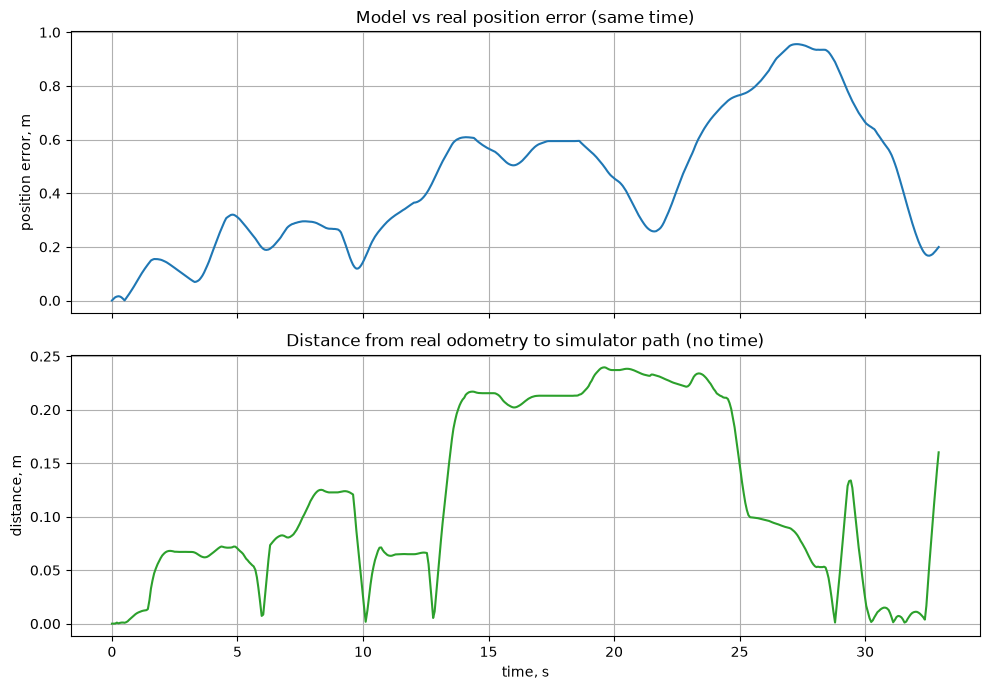

In [5]:
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

# time-free comparison: nearest simulator point for each real sample
d_path = np.array([np.hypot(x_s - xr, y_s - yr).min() for xr, yr in zip(x_r, y_r)])

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(t_r, err)
ax[0].set_ylabel('position error, m'); ax[0].set_title('Model vs real position error (same time)')
ax[1].plot(t_r, d_path, color='tab:green')
ax[1].set_ylabel('distance, m'); ax[1].set_title('Distance from real odometry to simulator path (no time)')
ax[1].set_xlabel('time, s')
plt.tight_layout(); plt.show()

end_err = np.hypot(x_r[-1] - x_s[-1], y_r[-1] - y_s[-1])
print(f'Final odometry error (sim vs real, same time): {err[-1]:.3f} m')
print(f'Max error (same time):                        {err.max():.3f} m')
print(f'End point distance (sim end vs real end):     {end_err:.3f} m')
print(f'Max distance to simulator path (no time):     {d_path.max():.3f} m')

## 5. Measured end point
The odometry end point is what the robot **believes**. The tape gives where it **is**.

In [6]:
odo_end = np.array([x_r[-1], y_r[-1]])
goal_end = WAYPOINTS[-1]
print(f'commanded end:      ({goal_end[0]:.3f}, {goal_end[1]:.3f}) m')
print(f'real odometry end:  ({odo_end[0]:.3f}, {odo_end[1]:.3f}) m')
if MEASURED_END is None:
    print('measured end:       not entered yet (set MEASURED_END in the first code cell)')
else:
    m = np.array(MEASURED_END)
    print(f'measured end:       ({m[0]:.3f}, {m[1]:.3f}) m')
    print(f'odometry error at the end (odometry vs tape): {np.hypot(*(odo_end - m)):.3f} m')

commanded end:      (0.450, -0.600) m
real odometry end:  (0.460, -0.762) m
measured end:       (0.460, -0.810) m
odometry error at the end (odometry vs tape): 0.048 m


## 6. Discussion

The real robot kept square corners but overshot every straight leg by 5–8 cm (simulator: under 3 mm), so its odometry ended 16 cm from the simulator end. This is robot dynamics, not odometry: the real loop ran every 61 ms instead of 20 ms and the motors coast after the power is cut. The robot does not know it is wrong: its real end point (0.46, −0.81) m is about 5 cm past its odometry end, and the robot cannot see this gap.